Tehtävä 10
Tarkastellaan signaalia

s(t)=sin(2π⋅0,2t)+0,5sin(2π⋅1,2t).
a) Muodosta signaali Pythonilla 100 Hz:n näytteenottotaajuudella aikavälillä 0≤t<30 s.

b) Poimi siitä havainnot sekunnin välein ja piirrä ne alkuperäisen signaalin päälle.

c) Mitkä alkuperäisen signaalin taajuudet voidaan erottaa 1 Hz:n näytteistyksellä?

d) Suodata korkeataajuinen komponentti pois ennen näytteenottotaajuuden pienentämistä. Valitse alipäästösuodatin, joka säilyttää 0,2 Hz:n komponentin ja vaimentaa 1,2 Hz:n komponenttia. Perustele suodattimen valinta ja tarkista sen vaikutus komponenttien amplitudeihin.

e) Vertaa suodatettua ja suodattamatonta tulosta. Selitä havaintosi.

<function matplotlib.pyplot.show(close=None, block=None)>

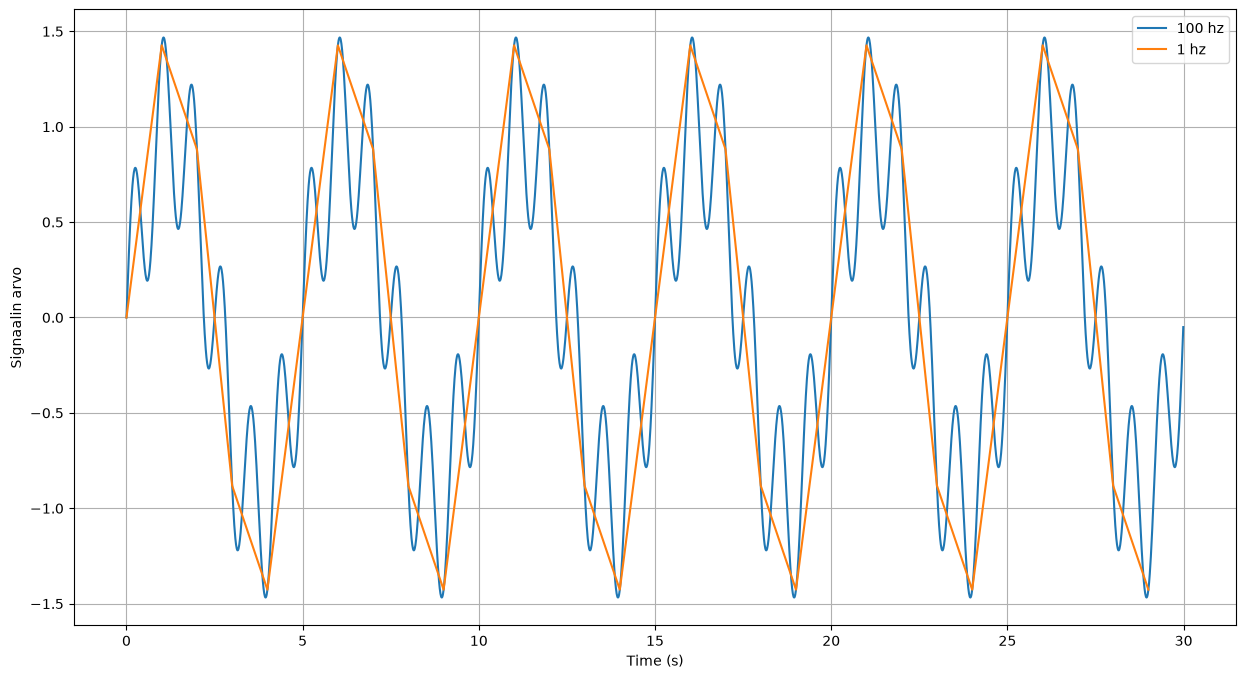

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(15,8))
            #Itse tehty vähän huonompi tapa
# t = np.linspace(0, 30, 3000) #määritys näytepisteiden perusteella 3000 näytettä
# t_sek = np.arange(0, 30, 1) #määritys näytteenotto välillä 30 näytettä

# s = np.sin(2*np.pi*0.2*t) + 0.5*np.sin(2*np.pi*1.2*t)
# s_sek = np.sin(2*np.pi*0.2*t_sek) + 0.5*np.sin(2*np.pi*1.2*t_sek)
# plt.plot(t, s, label="100 hz")
# plt.plot(t_sek, s_sek, label="1 hz")

#a) b)
pi = np.pi
f_s = 100 #näytteenottotaajuus
t_s = 1/f_s #näytteenottoväli
t_start = 0
t_end = 30
t= np.arange(t_start, t_end, t_s) #signaalin aikaleima 100Hz taajuudella 0,01s
s = np.sin(2*np.pi*0.2*t) + 0.5*np.sin(2*np.pi*1.2*t)

t_1 = t[::100] #joka sadas havainto eli sekunnin välein
s_1 = s[::100]

plt.plot(t, s, label="100 hz")
plt.plot(t_1, s_1, label="1 hz")

#c) 
#Nyqvistin teoreeman mukaan suurin havaittava taajuus on näytteenottotaajuuden puolikas.
#Eli tässä tapauksessa 0.5Hz



plt.xlabel('Time (s)')
plt.ylabel("Signaalin arvo")
plt.legend()
plt.grid()
plt.show


In [16]:
from scipy.signal import butter, filtfilt, sosfiltfilt

def butter_lowpass_filter(data, cutoff, fs, nyq, order):
    normal_cutoff = cutoff / nyq
    # Get the filter coefficients
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = filtfilt(b, a, data)
    return y
     
def butter_highpass_filter(data, cutoff, fs, nyq, order):
    normal_cutoff = cutoff / nyq 
    # Get the filter coefficients
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    y = filtfilt(b, a, data)
    return y

In [ ]:
#filttereiden parametrit
T= t_end - t_start #koko datan pituus
n = len(s) #Datapisteiden lukumäärä eli 3000
fs = f_s #datapisteiden lukumäärä 100
nyq = fs/2 #nyqvistin taajuus
order = 3 #kertaluku
cutoff = 0.8 #Cutt-off taajuus


<function matplotlib.pyplot.show(close=None, block=None)>

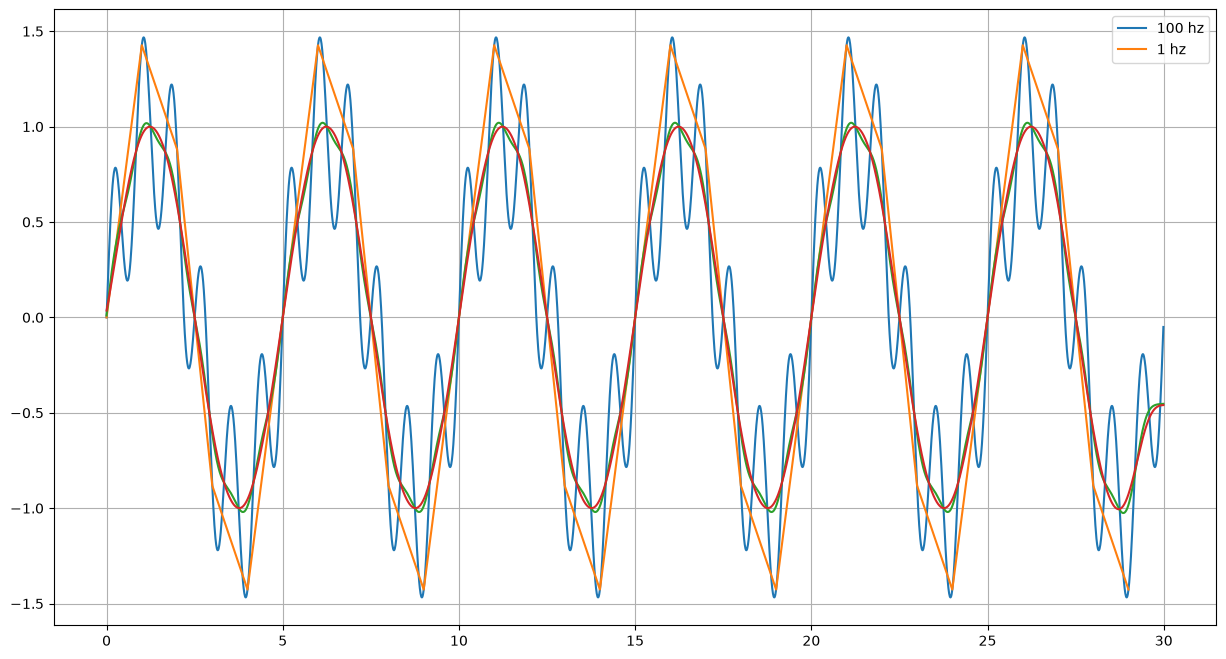

In [78]:
#filtteröidään funktio ja piirretään kuvaajat alkuperäisestä ja suodatetusta
s_filtered = butter_lowpass_filter(s, cutoff, fs, nyq, order) #suodatettu signaali
s_filteredd = butter_lowpass_filter(s_filtered, cutoff, fs, nyq, order)

plt.figure(figsize=(15,8))


plt.plot(t, s, label="100 hz")
plt.plot(t_1, s_1, label="1 hz")

plt.plot(t, s_filtered)
plt.plot(t, s_filteredd)
plt.legend()
plt.grid()
plt.show

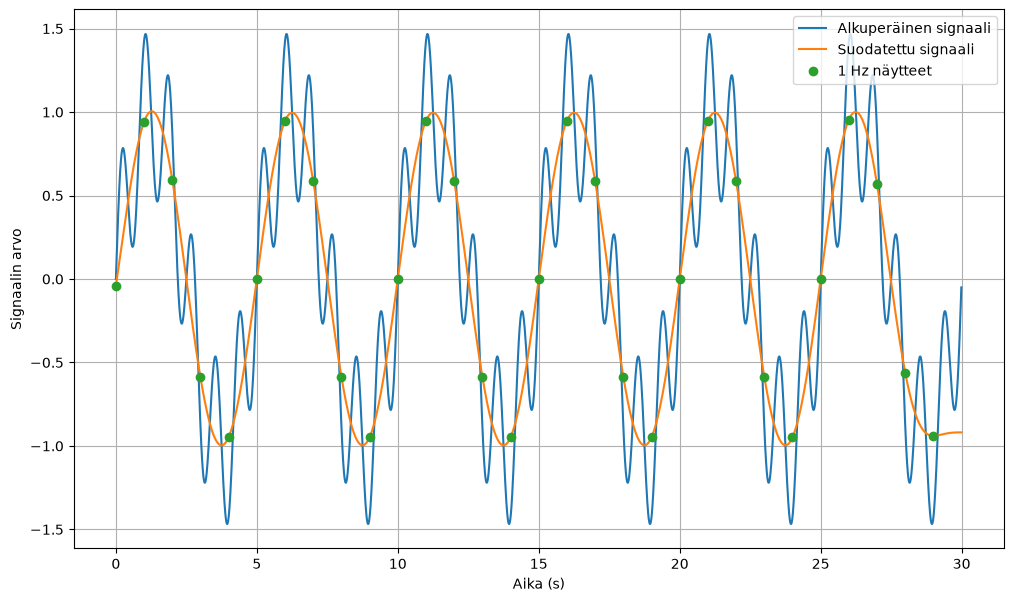

In [ ]:

fs = 100
t = np.linspace(0, 30, fs * 30, endpoint=False)

s = np.sin(2*np.pi*0.2*t) + 0.5*np.sin(2*np.pi*1.2*t)

# Alipäästösuodatin
fc = 0.4  # Rajataajuus 0,4 Hz
sos = butter(4, fc, btype="lowpass", fs=fs, output="sos")

# Suodatetaan signaali
s_filtered = sosfiltfilt(sos, s)

# Pienennetään näytteenottotaajuus 1 Hz:iin
t_1hz = t[::100]
s_1hz = s_filtered[::100]

# Piirretään kuvaajat
plt.figure(figsize=(12, 7))

plt.plot(t, s, label="Alkuperäinen signaali")
plt.plot(t, s_filtered, label="Suodatettu signaali")
plt.plot(t_1hz, s_1hz, "o", label="1 Hz näytteet")

plt.xlabel("Aika (s)")
plt.ylabel("Signaalin arvo")
plt.legend()
plt.grid()
plt.show()

#Kuvaaja havainnollistaa hyvin, miksi signaali kannattaa suodattaa ennen näytteenottotaajuuden pienentämistä.

#Ilman suodatusta 1,2 Hz:n komponentti laskostuisi 0,2 Hz:n taajuudeksi. Suodattamisen jälkeen sen vaikutus on hyvin pieni.
